# **Vision Transformer for Brain Tumor Image Classification**
In this notebook, we explore the powerful capabilities of Vision Transformers (ViT) in solving the complex task of Image Classification on the Brain Tumor dataset. Traditional Convolutional Neural Networks (CNNs) have been the go-to architecture for image-related tasks, but ViT brings a fresh perspective by introducing self-attention mechanisms inspired by the Transformer architecture originally designed for natural language processing.

The Brain Tumor dataset used in this notebook contains a collection of brain MRI scans, with each scan categorized into 4 classes. Our objective is to train a custom ViT model to accurately classify these MRI scans based on their content.

# What is a Vision Transformer (ViT)?
A Vision Transformer is a deep learning architecture that applies the Transformer model, initially designed for sequential data like text, to image data. This innovative approach divides an input image into fixed-size patches, which are then linearly embedded into vectors. These embedded vectors are treated as sequences and processed by Transformer layers, enabling ViT to capture both local and global dependencies within the image.

# About the Brain Tumor Dataset
The Brain Tumor dataset is a crucial collection of brain MRI scans acquired from patients with and without brain tumors. Each image in the dataset presents a unique challenge due to varying sizes, resolutions, and contrasts. Our goal is to leverage the ViT architecture to develop a robust classification model that can accurately identify the presence of brain tumors in these MRI scans.

# Custom ViT Model Architecture
In this notebook, we've designed a custom ViT model tailored for the Brain Tumor classification task. The model consists of an initial patch embedding layer, followed by multiple Transformer encoder layers. The self-attention mechanism of the Transformer allows the model to learn intricate spatial relationships between different regions of the brain images, contributing to its classification accuracy.

# Importing Libraries

In [1]:
import numpy as np
import tensorflow as tf
import tensorflow_addons as tfa
from tensorflow.keras.layers import Dense,Add, Dropout, Resizing,Rescaling,InputLayer,Flatten,LayerNormalization, MultiHeadAttention

from tensorflow.keras.callbacks import Callback, EarlyStopping,ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import layers,Model
import plotly.express as px
import matplotlib.pyplot as plt
from sklearn.metrics import multilabel_confusion_matrix,confusion_matrix
from tensorflow.keras.regularizers import L2
from tensorflow.keras.metrics import CategoricalAccuracy, TopKCategoricalAccuracy
from tensorflow.keras.layers.experimental.preprocessing import RandomRotation, RandomFlip, RandomContrast

from tensorflow.keras.preprocessing.image import load_img
#from tensorflow.keras.utils import plot_model
from functools import partial
import seaborn as sns
from sklearn.model_selection   import train_test_split
from keras.preprocessing.image import ImageDataGenerator

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/opt/conda/lib/python3.10/site-packages/tensorflow_io/python/ops/__init__.py:98: UserWarning: unable to load libtensorflow_io_plugins.so: unable to open file: libtensorflow_io_plugins.so, from paths: ['/opt/conda/lib/python3.10/site-packages/tensorflow_io/python/ops/libtensorflow_io_plugins.so']
caused by: ['/opt/conda/lib/python3.10/site-packages/tensorflow_io/python/ops/libtensorflow_io_plugins.so: undefined symbol: _ZN3tsl6StatusC1EN10tensorflow5error4CodeESt17basic_string_viewIcSt11char_traitsIcEENS_14SourceLocationE']
  warnings.warn(f"unable to load libtensorflow_io_plugins.so: {e}")
/opt/conda/lib/python3.10/site-packages/tensorflow_io/python/ops/__init__.py:104: UserWarning: file system plugins are not loaded: unable to open file: l

In [2]:
learning_rate = 0.0001
class_name=['glioma','meningioma','notumor','pituitary']
weight_decay = 0.0001
num_classes=4
batch_size =32
num_epochs = 200
image_size = 224  # We'll resize input images to this size
patch_size = 16  # Size of the patches to be extract from the input images
num_patches = (image_size // patch_size) ** 2
projection_dim = 256 
Num_heads = 4
transformer_units = [
    projection_dim * 2,
    projection_dim,
]  # Size of the transformer layers
num_layers = 15
Hidden_size=64
mlp_head_units = 1024

# Data Prepartion

In [3]:
train_data='/kaggle/input/brain-tumor-mri-dataset/Training'
test_data='/kaggle/input/brain-tumor-mri-dataset/Testing'

In [4]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_data,
    labels='inferred',
    label_mode='categorical',
    class_names=class_name,
    color_mode='grayscale',
    batch_size=batch_size,
    image_size=(image_size,image_size),
    shuffle=True,
    seed=99,
    validation_split=0.2,  
    subset='training',
)
val_dataset = tf.keras.utils.image_dataset_from_directory(
    train_data,
    labels='inferred',
    label_mode='categorical',
    class_names=class_name,
    color_mode='grayscale',
    batch_size=batch_size,
    image_size=(image_size,image_size),
    shuffle=True,
    seed=99,
    validation_split=0.2,  # Use 20% of the data for validation
    subset='validation',
)
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_data,
    labels='inferred',
    label_mode='categorical',
    class_names=class_name,
    color_mode='grayscale',
    batch_size=batch_size,
    image_size=(image_size,image_size),
    shuffle=True,
    seed=99,
)

Found 5712 files belonging to 4 classes.
Using 4570 files for training.
Found 5712 files belonging to 4 classes.
Using 1142 files for validation.
Found 1311 files belonging to 4 classes.


# **Data Visualization**


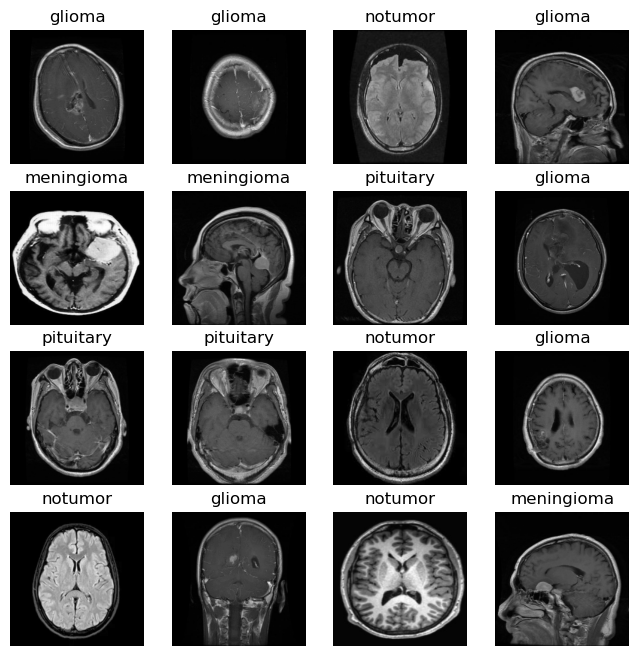

In [5]:
plt.figure(figsize=(8, 8))
for images, labels in train_dataset.take(10):
    for i in range(min(16, len(images))): 
        ax = plt.subplot(4, 4, i + 1)
        plt.imshow(images[i] / 255., cmap='gray')  
        plt.title(class_name[tf.argmax(labels[i]).numpy()])
        plt.axis("off")

plt.show()


# Data Augmentation

In [6]:
augment_layers = tf.keras.Sequential([
    RandomRotation(factor=(-0.25, 0.2501)),
   RandomFlip("horizontal_and_vertical",seed=42),  # Specify a seed for reproducibility
])

In [7]:
# Define a custom preprocessing function
def process_data(image, label):
    augmented_image=augment_layers(image)
    resized_image = tf.image.resize(augmented_image, size=(image_size, image_size))
    return resized_image, label

# Apply augmentation and preprocessing to the dataset
training_dataset = (
    train_dataset.
    shuffle(1000)
    .map(partial(process_data),num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

In [8]:
vali_dataset=(
   val_dataset.shuffle(1000)
    .prefetch(tf.data.AUTOTUNE)


)

In [9]:
input_tensor = next(iter(training_dataset))[0]

In [10]:
patche=tf.image.extract_patches(images=input_tensor,
                               sizes=[1,patch_size,patch_size,1],
                                strides=[1,patch_size,patch_size,1],
                                rates=[1,1,1,1],
                                 padding='VALID')
                                

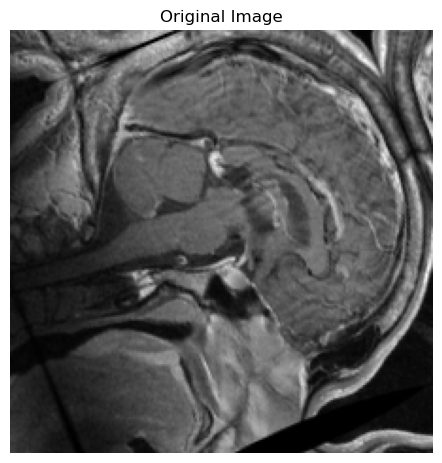

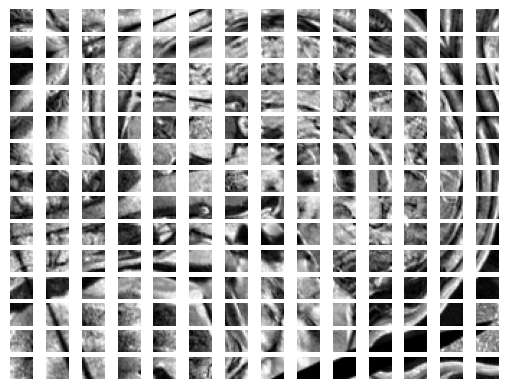

In [11]:


plt.figure(figsize=(12, 12))

batch_size, patch_rows, patch_cols, channels = patche.shape
plt.subplot(1, 2, 1)
plt.imshow(input_tensor[0],cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.show()
for i in range(patch_rows):
    for j in range(patch_cols):
        ax = plt.subplot(patch_rows, patch_cols, i * patch_cols + j + 1)
        plt.imshow(patche[0, i, j, :].numpy().reshape (patch_size,patch_size, 1),cmap='gray')
        plt.axis("off")

plt.show()


# VIT MODEL

In [12]:
class PatchEncoder(layers.Layer):
    def __init__(self, patch_size,Hidden_size):
        super(PatchEncoder, self).__init__(name='patch_encoder')
        self.linear_projection=Dense(Hidden_size)
        self.position_embedding = layers.Embedding(
            input_dim=num_patches, output_dim=Hidden_size
        )
        
        self.num_patches=num_patches

    def call(self, image):
        batch_size = tf.shape(image)[0]  # Retrieve batch size
        patches=tf.image.extract_patches(images=image,
                                sizes=[1,patch_size,patch_size,1],
                                strides=[1,patch_size,patch_size,1],
                                rates=[1,1,1,1],
                                 padding='VALID'
                                )
       
        patch_dims = patches.shape[-1]
        patches = tf.reshape(patches, [batch_size, -1, patches.shape[-1]])
        embedding_input=tf.range(start=0,limit =self.num_patches,delta=1)
        output=self.linear_projection(patches)+ self.position_embedding(embedding_input)
        return output

In [13]:
class TransformerEncoder(layers.Layer):
    def __init__(self, Num_heads,Hidden_size):
        super(TransformerEncoder, self).__init__(name='transformer_encoder')
        self.layer_norm_1=LayerNormalization()
        self.layer_norm_2=LayerNormalization()
        
        self.multi_head_att=MultiHeadAttention(Num_heads,Hidden_size)
        
        self.dense_1=Dense(Hidden_size,activation=tf.nn.gelu)
        self.dense_2=Dense(Hidden_size,activation=tf.nn.gelu)


    def call(self, input):
        x=self.layer_norm_1(input)
        x1=self.multi_head_att(x,x)
        
        x1=Add()([x1,input])
        x2=self.layer_norm_2(x1)
        x2=self.dense_1(x2)
        output=self.dense_1(x2)
        output=Add()([output,x1])
      
        return output

In [14]:
class VIT(tf.keras.Model):
    def __init__(self, Num_heads, Hidden_size, num_patches, num_layers, mlp_head_units):
        super(VIT, self).__init__(name='vision_transformer')
        self.num_layers = num_layers
        self.patch_encoder = PatchEncoder(patch_size, Hidden_size)
        self.trans_encoder = [TransformerEncoder(Num_heads, Hidden_size) for _ in range(num_layers)]
        self.flatten = layers.Flatten()
        self.dense_1 = layers.Dense(mlp_head_units, activation='relu')
        self.dense_2 = layers.Dense(mlp_head_units, activation='relu')
        self.dense_3 = layers.Dense(num_classes, activation='softmax')

    def call(self, inputs):
        x = self.patch_encoder(inputs)  # Get encoded patches
        for i in range(self.num_layers):
            x = self.trans_encoder[i](x)  # Apply transformer encoder layers
        
        x = self.flatten(x)
        x = self.dense_1(x)
        x = self.dense_2(x)
        output = self.dense_3(x)
        return output

# Create and compile the VIT model
vit = VIT(Num_heads, Hidden_size, num_patches, num_layers, mlp_head_units)


# Model Training

In [15]:
loss_funcion=tf.keras.losses.CategoricalCrossentropy(
    from_logits=False,

)

In [16]:
metrics=[CategoricalAccuracy(name= 'accuracy'),TopKCategoricalAccuracy(k=2,name='top_k_accuracy')]

In [17]:
vit.compile(
    optimizer=Adam(learning_rate=learning_rate),
                   loss=loss_funcion,
                   metrics=metrics

)

In [18]:
checkpoint_filepath = "/kaggle/working/"
checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
        checkpoint_filepath,
        monitor="val_accuracy",
        save_best_only=True,
        save_weights_only=True,
    )

In [19]:
# Train the model
history = vit.fit(
    training_dataset,
    epochs=num_epochs,
    verbose=1,
    validation_data=vali_dataset,
    callbacks=[checkpoint_callback]
    
)

Epoch 1/200
143/143 [==============================] - 72s 171ms/step - loss: 22.9940 - accuracy: 0.4309 - top_k_accuracy: 0.7245 - val_loss: 5.3994 - val_accuracy: 0.5088 - val_top_k_accuracy: 0.7741
Epoch 2/200
143/143 [==============================] - 24s 147ms/step - loss: 4.6041 - accuracy: 0.5398 - top_k_accuracy: 0.8031 - val_loss: 3.8366 - val_accuracy: 0.5508 - val_top_k_accuracy: 0.8126
Epoch 3/200
143/143 [==============================] - 24s 147ms/step - loss: 2.9743 - accuracy: 0.5849 - top_k_accuracy: 0.8306 - val_loss: 2.9369 - val_accuracy: 0.5998 - val_top_k_accuracy: 0.8555
Epoch 4/200
143/143 [==============================] - 24s 148ms/step - loss: 2.3384 - accuracy: 0.6105 - top_k_accuracy: 0.8484 - val_loss: 2.1296 - val_accuracy: 0.6366 - val_top_k_accuracy: 0.8494
Epoch 5/200
143/143 [==============================] - 23s 141ms/step - loss: 1.8512 - accuracy: 0.6263 - top_k_accuracy: 0.8567 - val_loss: 1.8541 - val_accuracy: 0.5972 - val_top_k_accuracy: 0.8450

# TRAINING CODE 

In [20]:
import numpy as np
import time
import os

# Convert test_dataset to a list of batches
test_batches = list(test_dataset)
num_total_batches = len(test_batches)

# Use only 20% of the test batches
num_test_batches = max(1, int(0.2 * num_total_batches)) 
selected_batches = test_batches[:num_test_batches]

# Combine batches into numpy arrays
X_test_20 = []
y_test_20 = []

for batch_images, batch_labels in selected_batches:
    X_test_20.append(batch_images.numpy())
    y_test_20.append(batch_labels.numpy())

X_test_20 = np.concatenate(X_test_20, axis=0)
y_test_20 = np.concatenate(y_test_20, axis=0)

# Inference timing
start_time = time.time()
predictions = vit.predict(X_test_20)
end_time = time.time()

total_time = end_time - start_time
avg_time = total_time / len(X_test_20)

print(f"\nTotal inference time on 20% test data: {total_time:.4f} seconds")
print(f"Average inference time per sample: {avg_time:.6f} seconds")

# Convert one-hot labels to class indices
true_indices = np.argmax(y_test_20, axis=1)
predicted_indices = np.argmax(predictions, axis=1)

# Save class index-to-label mapping
with open("class_index_to_label.txt", "w") as f:
    for i, label in enumerate(class_name):
        f.write(f"{i}: {label}\n")

# Save prediction results
with open("prediction_results.txt", "w") as f:
    f.write("SampleIndex\tPredictedIndex\tPredictedLabel\n")
    for i, idx in enumerate(predicted_indices):
        f.write(f"{i}\t{idx}\t{class_name[idx]}\n")

# Save paths to output files
with open("paths.txt", "w") as f:
    f.write("/kaggle/working/class_index_to_label.txt\n")
    f.write("/kaggle/working/prediction_results.txt\n")

print("\nOutput files saved to /kaggle/working/:")
print(" - class_index_to_label.txt")
print(" - prediction_results.txt")
print(" - paths.txt")


8/8 [==============================] - 2s 50ms/step

Total inference time on 20% test data: 2.2638 seconds
Average inference time per sample: 0.008843 seconds

Output files saved to /kaggle/working/:
 - class_index_to_label.txt
 - prediction_results.txt
 - paths.txt


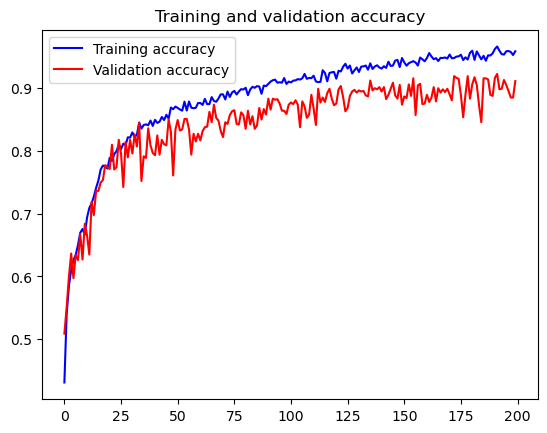

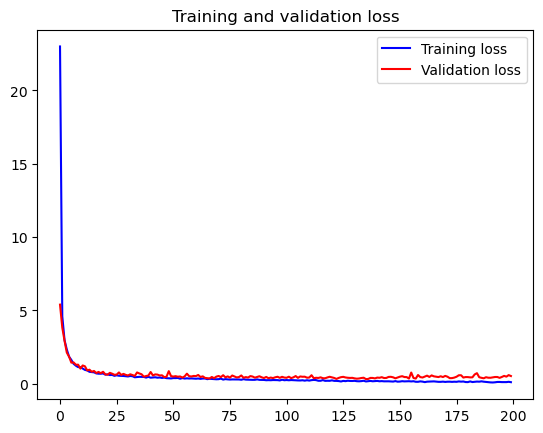

In [21]:
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(accuracy))
plt.plot(epochs, accuracy, 'b', label='Training accuracy')
plt.plot(epochs, val_accuracy, 'r', label='Validation accuracy')

plt.title('Training and validation accuracy')
plt.legend()
plt.figure()
plt.plot(epochs, loss, 'b', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')

plt.title('Training and validation loss')
plt.legend()
plt.show()

# Saving Model

In [22]:
vit.save('/kaggle/working/')

In [23]:
vit.save_weights('/kaggle/working/')

# Prediction

In [24]:
vit.evaluate(test_dataset)

41/41 [==============================] - 3s 57ms/step - loss: 0.5821 - accuracy: 0.9031 - top_k_accuracy: 0.9893


[0.582135021686554, 0.9031273722648621, 0.9893211126327515]

In [25]:
predicted=[]
labels=[]
for im, label in test_dataset:
    predicted.append(vit(im))
    labels.append(label.numpy())

In [26]:
pred= np.concatenate([np.argmax(predicted[:-1],axis=-1).flatten(),np.argmax(predicted[-1],axis=-1).flatten()])
lab= np.concatenate([np.argmax(labels[:-1],axis=-1).flatten(),np.argmax(labels[-1],axis=-1).flatten()])

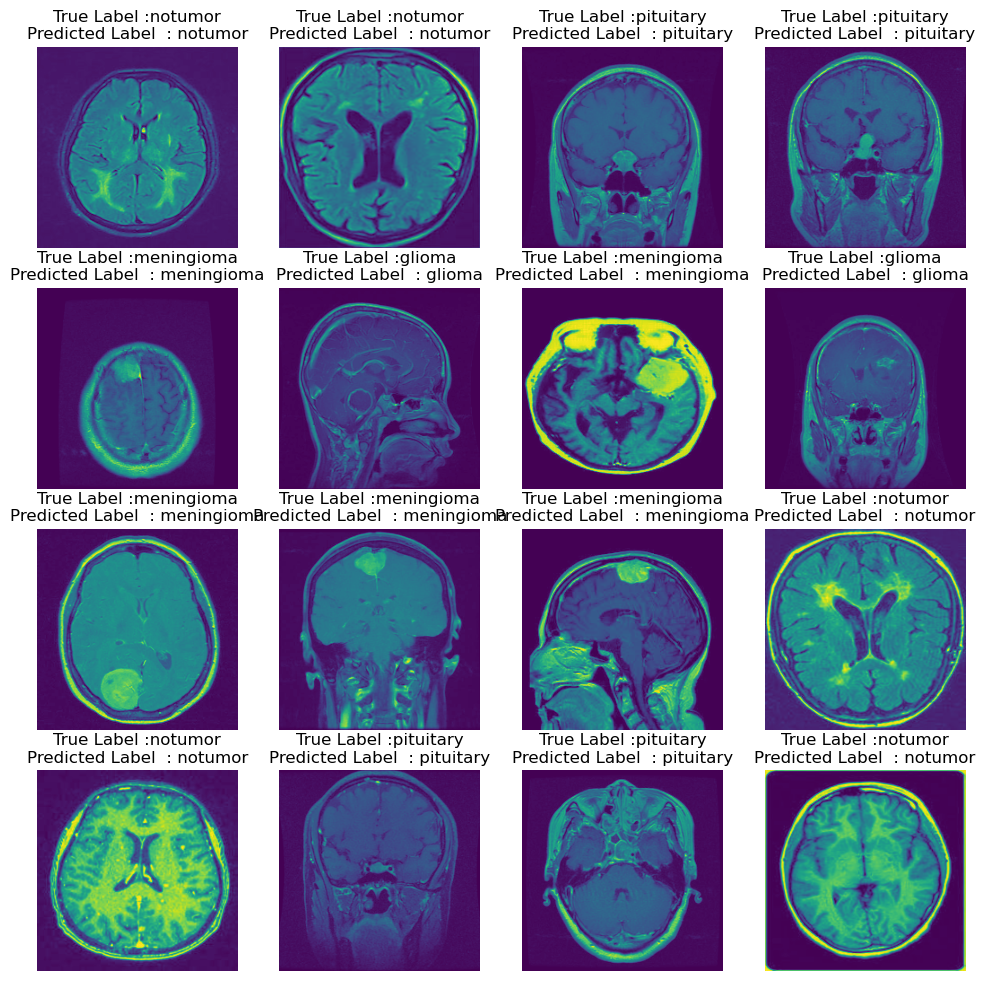

In [27]:
plt.figure(figsize=(12,12))
for   images,labels in  test_dataset.take(10):
  for i   in range(16):
   ax=plt.subplot(4,4,i+1)

   plt.imshow(images[i]/255.)
   plt.title("True Label :"+ class_name[tf.argmax(labels[i],axis=0).numpy()] + "\n" + "Predicted Label  : " + class_name[tf.argmax(vit(tf.expand_dims(images[i],axis=0)),axis= -1).numpy()[0]])
   plt.axis("off")

# Confusion Matrix

[[243  54   0   3]
 [ 12 253  28  13]
 [  0   5 399   1]
 [  0  11   0 289]]


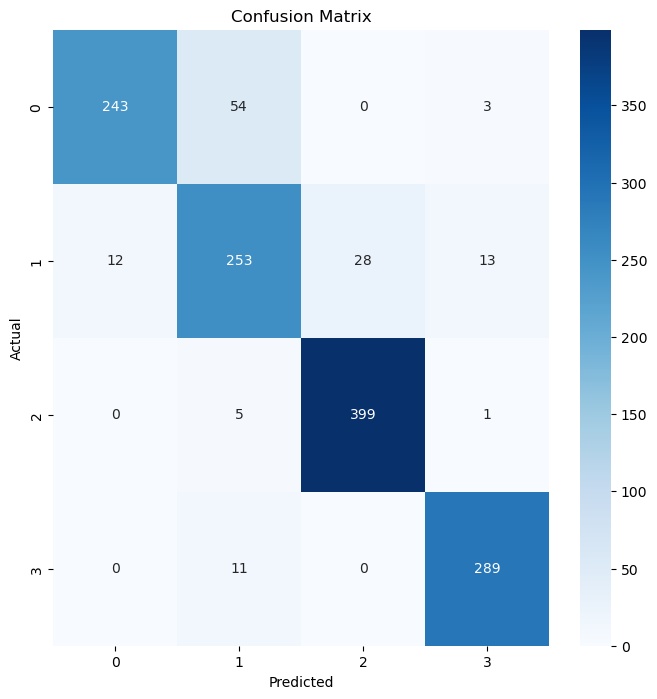

In [28]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Set global font to Times New Roman
plt.rcParams["font.family"] = "Times New Roman"

cm = confusion_matrix(lab, pred)
print(cm)

plt.figure(figsize=(8, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()


In [29]:
# Required imports
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import plot_model
import matplotlib.pyplot as plt
import os

# Build the model with a sample input shape
vit.build(input_shape=(None, 224, 224, 1)) 

# 1. Print full model summary
print("Model Summary:\n")
vit.summary()

# 2. Print all layers with names and types
print("\n Layer Names and Types:")
for layer in vit.layers:
    print(f" - {layer.name}: {layer.__class__.__name__}")

# 3. Print weights and their shapes per layer
print("\n Layer Weights and Shapes:")
for layer in vit.layers:
    if layer.weights:
        print(f"\nLayer: {layer.name}")
        for weight in layer.weights:
            print(f"    {weight.name} | shape: {weight.shape}")

# 4. Print trainable and non-trainable parameter counts
trainable_params = np.sum([np.prod(w.shape) for w in vit.trainable_weights])
non_trainable_params = np.sum([np.prod(w.shape) for w in vit.non_trainable_weights])

print(f"\n Trainable Parameters: {trainable_params:,}")
print(f" Non-trainable Parameters: {non_trainable_params:,}")
print(f" Total Parameters: {vit.count_params():,}")


Model Summary:

Model: "vision_transformer"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 patch_encoder (PatchEncoder  multiple                 28992     
 )                                                               
                                                                 
 transformer_encoder (Transf  multiple                 70784     
 ormerEncoder)                                                   
                                                                 
 transformer_encoder (Transf  multiple                 70784     
 ormerEncoder)                                                   
                                                                 
 transformer_encoder (Transf  multiple                 70784     
 ormerEncoder)                                                   
                                                                 
 transformer_encoder (Transf  mu

In [30]:
pip install tensorboard


Note: you may need to restart the kernel to use updated packages.


In [31]:
import tensorflow as tf
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

# === Step 1: Run once to build the model ===
input_data = tf.random.normal([1, 224, 224, 1])  # Grayscale image
_ = vit(input_data)  # Call the model once

# === Step 2: Create concrete function directly ===
concrete_func = tf.function(vit).get_concrete_function(
    tf.TensorSpec(input_data.shape, dtype=input_data.dtype))

# === Step 3: Freeze graph ===
frozen_func = convert_variables_to_constants_v2(concrete_func)
graph_def = frozen_func.graph.as_graph_def()

# === Step 4: Profile FLOPs ===
with tf.Graph().as_default() as graph:
    tf.graph_util.import_graph_def(graph_def, name="")
    run_meta = tf.compat.v1.RunMetadata()
    opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()

    flops = tf.compat.v1.profiler.profile(
        graph=graph, run_meta=run_meta, cmd="op", options=opts)

    print(f"Total FLOPs: {flops.total_float_ops:,}")
    print(f"GFLOPs (approx): {flops.total_float_ops / 1e9:.3f} GFLOPs")



=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          
-account_displayed_op_only  true
-select                     float_ops
-output                     stdout:

==================Model Analysis Report======================

Doc:
op: The nodes are operation kernel type, such as MatMul, Conv2D. Graph nodes belonging to the same type are aggregated together.
flops: Number of float operations. Note: Please read the implementation for th

# NEW PARAMETER SUMMARY TABLE

In [32]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# === Step 1: Dummy Input ===
dummy_input = tf.zeros((1, 224, 224, 1))  # grayscale image
x = dummy_input
layer_info = []

# === Step 2: Patch Encoder ===
x = vit.patch_encoder(x)
layer_info.append({
    "Name": "patch_encoder",
    "Type": vit.patch_encoder.__class__.__name__,
    "Output Shape": str(x.shape),
    "Number of Parameters": vit.patch_encoder.count_params(),
    "Connected to": "input"
})

# === Step 3: Transformer Encoder Blocks ===
for i, encoder in enumerate(vit.trans_encoder):
    x = encoder(x)
    try:
        params = encoder.count_params()
    except:
        params = "-"
    layer_info.append({
        "Name": f"transformer_encoder_{i}",
        "Type": encoder.__class__.__name__,
        "Output Shape": str(x.shape),
        "Number of Parameters": params,
        "Connected to": f"transformer_encoder_{i-1}" if i > 0 else "patch_encoder"
    })

# === Step 4: Remaining Layers ===
x = vit.flatten(x)
layer_info.append({
    "Name": "flatten",
    "Type": vit.flatten.__class__.__name__,
    "Output Shape": str(x.shape),
    "Number of Parameters": vit.flatten.count_params(),
    "Connected to": f"transformer_encoder_{len(vit.trans_encoder)-1}"
})

x = vit.dense_1(x)
layer_info.append({
    "Name": "dense_1",
    "Type": vit.dense_1.__class__.__name__,
    "Output Shape": str(x.shape),
    "Number of Parameters": vit.dense_1.count_params(),
    "Connected to": "flatten"
})

x = vit.dense_2(x)
layer_info.append({
    "Name": "dense_2",
    "Type": vit.dense_2.__class__.__name__,
    "Output Shape": str(x.shape),
    "Number of Parameters": vit.dense_2.count_params(),
    "Connected to": "dense_1"
})

x = vit.dense_3(x)
layer_info.append({
    "Name": "dense_3",
    "Type": vit.dense_3.__class__.__name__,
    "Output Shape": str(x.shape),
    "Number of Parameters": vit.dense_3.count_params(),
    "Connected to": "dense_2"
})

# === Step 5: Create and Display Table ===
df = pd.DataFrame(layer_info)
df = df[["Name", "Type", "Output Shape", "Number of Parameters", "Connected to"]]

# === Global Font Setting: Times New Roman ===
plt.rcParams['font.family'] = 'Times New Roman'

# === Display in Notebook (optional) ===
from IPython.display import display
display(df.style.set_table_styles(
    [{'selector': 'td', 'props': [('font-family', 'Times New Roman')]},
     {'selector': 'th', 'props': [('font-family', 'Times New Roman')]}]
))

# === Step 6: Print Total Parameter Summary ===
trainable_params = np.sum([np.prod(v.shape) for v in vit.trainable_weights])
non_trainable_params = np.sum([np.prod(v.shape) for v in vit.non_trainable_weights])
total_params = vit.count_params()

print(f"Trainable Parameters: {trainable_params:,}")
print(f"Non-Trainable Parameters: {non_trainable_params:,}")
print(f"Total Parameters: {total_params:,}")


,Name,Type,Output Shape,Number of Parameters,Connected to
0,patch_encoder,PatchEncoder,"(1, 196, 64)",28992,input
1,transformer_encoder_0,TransformerEncoder,"(1, 196, 64)",70784,patch_encoder
2,transformer_encoder_1,TransformerEncoder,"(1, 196, 64)",70784,transformer_encoder_0
3,transformer_encoder_2,TransformerEncoder,"(1, 196, 64)",70784,transformer_encoder_1
4,transformer_encoder_3,TransformerEncoder,"(1, 196, 64)",70784,transformer_encoder_2
5,transformer_encoder_4,TransformerEncoder,"(1, 196, 64)",70784,transformer_encoder_3
6,transformer_encoder_5,TransformerEncoder,"(1, 196, 64)",70784,transformer_encoder_4
7,transformer_encoder_6,TransformerEncoder,"(1, 196, 64)",70784,transformer_encoder_5
8,transformer_encoder_7,TransformerEncoder,"(1, 196, 64)",70784,transformer_encoder_6
9,transformer_encoder_8,TransformerEncoder,"(1, 196, 64)",70784,transformer_encoder_7


Trainable Parameters: 14,990,532
Non-Trainable Parameters: 0.0
Total Parameters: 14,990,532


In [33]:
encoder0 = vit.trans_encoder[0]

for i, sub in enumerate(encoder0.submodules):
    print(f"{i:02d}: {sub.name}")


00: layer_normalization
01: layer_normalization_1
02: multi_head_attention
03: dense_1
04: dense_2
05: dropout
06: key
07: attention_output
08: query
09: value
10: softmax


In [34]:
import numpy as np
import tensorflow as tf
from PIL import Image

# === Load a single grayscale test image ===
image_path = "/kaggle/input/brain-tumor-mri-dataset/Training/glioma/Tr-glTr_0000.jpg" 
image = Image.open(image_path).convert("L").resize((224, 224))  # Grayscale
image_np = np.array(image).astype(np.float32) / 255.0  # Normalize to [0,1]
image_np = image_np[..., np.newaxis]  # shape: (224, 224, 1)
image_tensor = tf.convert_to_tensor(image_np)[tf.newaxis, ...]  # shape: (1, 224, 224, 1)

# === Get patch embeddings ===
patch_embeddings = vit.patch_encoder(image_tensor)  # shape: (1, 196, 64)

# === Extract the first TransformerEncoder block ===
encoder0 = vit.trans_encoder[0]

# This is the input to MHSA → output of LayerNorm1 ===
x_norm = encoder0.layer_norm_1(patch_embeddings)  # shape: (1, 196, 64)
x_norm_np = tf.squeeze(x_norm, axis=0).numpy()     # shape: (196, 64)

# === Save the actual input to MHSA ===
np.savetxt("input_tensor_196x64.txt", x_norm_np, fmt="%.8f", delimiter=",")
print("Saved input to HLS MHSA: input_tensor_196x64.txt")


Saved input to HLS MHSA: input_tensor_196x64.txt


In [35]:
import numpy as np
import os

# === Output directory ===
output_dir = "/kaggle/working/weights"
os.makedirs(output_dir, exist_ok=True)

# === Access the first encoder's MHSA block ===
encoder0 = vit.trans_encoder[0]
mhsa = encoder0.multi_head_att

# === Extract Wq, Wk, Wv kernels from weights ===
# weights[0] = Wq kernel (64, 4, 64)
# weights[2] = Wk kernel (64, 4, 64)
# weights[4] = Wv kernel (64, 4, 64)
Wq = mhsa.weights[0].numpy()
Wk = mhsa.weights[2].numpy()
Wv = mhsa.weights[4].numpy()

# === Save per-head kernels ===
for head in range(4):
    np.savetxt(f"{output_dir}/wq_head{head+1}.txt", Wq[:, head, :], fmt="%.8f", delimiter=",")
    np.savetxt(f"{output_dir}/wk_head{head+1}.txt", Wk[:, head, :], fmt="%.8f", delimiter=",")
    np.savetxt(f"{output_dir}/wv_head{head+1}.txt", Wv[:, head, :], fmt="%.8f", delimiter=",")

print("Saved Wq, Wk, Wv weights for all 4 heads to:", output_dir)


Saved Wq, Wk, Wv weights for all 4 heads to: /kaggle/working/weights


In [36]:
import numpy as np
import os

# === Output directory ===
bias_dir = "/kaggle/working/biases"
os.makedirs(bias_dir, exist_ok=True)

# === Access MHSA block from first encoder ===
encoder0 = vit.trans_encoder[0]
mhsa = encoder0.multi_head_att

# === Bias indices in mhsa.weights ===
# weights[1] = bq: shape (4, 64)
# weights[3] = bk: shape (4, 64)
# weights[5] = bv: shape (4, 64)
bq = mhsa.weights[1].numpy()  # shape: (4, 64)
bk = mhsa.weights[3].numpy()
bv = mhsa.weights[5].numpy()

# === Save each head's bias to file ===
for head in range(4):
    np.savetxt(f"{bias_dir}/bq_head{head+1}.txt", bq[head], fmt="%.8f")
    np.savetxt(f"{bias_dir}/bk_head{head+1}.txt", bk[head], fmt="%.8f")
    np.savetxt(f"{bias_dir}/bv_head{head+1}.txt", bv[head], fmt="%.8f")

print("Saved bq, bk, bv biases for all 4 heads to:", bias_dir)


Saved bq, bk, bv biases for all 4 heads to: /kaggle/working/biases


In [37]:
import numpy as np
import os

# === Output directory ===
wo_dir = "/kaggle/working/attention_output"
os.makedirs(wo_dir, exist_ok=True)

# === Access MHSA block from encoder ===
encoder0 = vit.trans_encoder[0]
mhsa = encoder0.multi_head_att

# === Get raw weights ===
Wo = mhsa.weights[6].numpy()  # shape: (4, 64, 64)
bo = mhsa.weights[7].numpy()  # shape: (64,)

# === Correct reshape: (4, 64, 64) → (256, 64) ===
Wo_reshaped = Wo.transpose(1, 0, 2).reshape(256, 64)

# === Save for HLS ===
np.savetxt(f"{wo_dir}/wo.txt", Wo_reshaped, fmt="%.8f", delimiter=",")
np.savetxt(f"{wo_dir}/bo.txt", bo, fmt="%.8f")

print("Saved flattened Wo (256x64) and bo (64,) to:", wo_dir)

Saved flattened Wo (256x64) and bo (64,) to: /kaggle/working/attention_output


In [38]:
# Call MHSA with dummy data to initialize weights and shape
encoder0 = vit.trans_encoder[0]

# Assume your input is x_norm (shape: (1, 196, 64))
x_norm = encoder0.layer_norm_1(patch_embeddings)

# Run attention once
mhsa_output = encoder0.multi_head_att(x_norm, x_norm)

# Now safely check shape
print("MHSA output shape:", mhsa_output.shape)


MHSA output shape: (1, 196, 64)


In [39]:
mhsa = encoder0.multi_head_att
wo = mhsa.weights[6]  # Wo kernel: shape = (256, 64)
print("Wo (attention output projection) shape:", wo.shape)


Wo (attention output projection) shape: (4, 64, 64)


In [40]:
import tensorflow as tf
import pandas as pd

# === Step 1: Access the first TransformerEncoder block ===
encoder0 = vit.trans_encoder[0]
mhsa = encoder0.multi_head_att

# === Step 2: Get all weight names and shapes ===
weight_info = []
for w in mhsa.weights:
    weight_info.append({
        "Name": w.name,
        "Shape": w.shape.as_list()
    })

# === Step 3: Add known roles based on name patterns ===
def identify_role(name):
    if "query/kernel" in name:
        return "Query weight (Wq)"
    elif "query/bias" in name:
        return "Query bias (bq)"
    elif "key/kernel" in name:
        return "Key weight (Wk)"
    elif "key/bias" in name:
        return "Key bias (bk)"
    elif "value/kernel" in name:
        return "Value weight (Wv)"
    elif "value/bias" in name:
        return "Value bias (bv)"
    elif "attention_output/kernel" in name:
        return "Output projection weight (Wo)"
    elif "attention_output/bias" in name:
        return "Output projection bias"
    else:
        return "Other"

# Add roles
for w in weight_info:
    w["Role"] = identify_role(w["Name"])

# === Step 4: Convert to DataFrame and display ===
df = pd.DataFrame(weight_info)
df.columns = ["Name", "Shape", "Role"]
df


,Name,Shape,Role
0,vision_transformer/transformer_encoder/multi_h...,"[64, 4, 64]",Query weight (Wq)
1,vision_transformer/transformer_encoder/multi_h...,"[4, 64]",Query bias (bq)
2,vision_transformer/transformer_encoder/multi_h...,"[64, 4, 64]",Key weight (Wk)
3,vision_transformer/transformer_encoder/multi_h...,"[4, 64]",Key bias (bk)
4,vision_transformer/transformer_encoder/multi_h...,"[64, 4, 64]",Value weight (Wv)
5,vision_transformer/transformer_encoder/multi_h...,"[4, 64]",Value bias (bv)
6,vision_transformer/transformer_encoder/multi_h...,"[4, 64, 64]",Output projection weight (Wo)
7,vision_transformer/transformer_encoder/multi_h...,[64],Output projection bias


In [41]:
import numpy as np
import tensorflow as tf
from PIL import Image

# === Load and preprocess a single grayscale image ===
image_path = "/kaggle/input/brain-tumor-mri-dataset/Training/glioma/Tr-glTr_0000.jpg"
image = Image.open(image_path).convert("L").resize((224, 224))
image_np = np.array(image).astype(np.float32) / 255.0  # Normalize
image_np = image_np[..., np.newaxis]  # shape: (224, 224, 1)
image_tensor = tf.convert_to_tensor(image_np)[tf.newaxis, ...]  # shape: (1, 224, 224, 1)

# === Pass through PatchEncoder ===
patch_embeddings = vit.patch_encoder(image_tensor)  # shape: (1, 196, 64)

# === Extract the first TransformerEncoder block ===
encoder0 = vit.trans_encoder[0]

# === Output of LayerNorm before MHSA (HLS input) ===
x_norm = encoder0.layer_norm_1(patch_embeddings)  # shape: (1, 196, 64)

# === Final output of MHSA block (HLS output target) ===
mhsa_output = encoder0.multi_head_att(x_norm, x_norm)  # shape: (1, 196, 64)
mhsa_output_np = tf.squeeze(mhsa_output, axis=0).numpy()  # shape: (196, 64)

# === Save output to text file ===
np.savetxt("mhsa_output_196x64.txt", mhsa_output_np, fmt="%.8f", delimiter=",")
print("Saved MHSA output: mhsa_output_196x64.txt")


Saved MHSA output: mhsa_output_196x64.txt


In [42]:
from IPython.display import FileLink

# First, zip the folder
!zip -r output.zip /kaggle/working/

# Generate clickable download link
FileLink(r'output.zip')

  adding: kaggle/working/ (stored 0%)
  adding: kaggle/working/.data-00000-of-00001 (deflated 11%)
  adding: kaggle/working/mhsa_output_196x64.txt (deflated 56%)
  adding: kaggle/working/__notebook__.ipynb (deflated 86%)
  adding: kaggle/working/prediction_results.txt (deflated 81%)
  adding: kaggle/working/saved_model.pb (deflated 92%)
  adding: kaggle/working/fingerprint.pb (stored 0%)
  adding: kaggle/working/class_index_to_label.txt (deflated 4%)
  adding: kaggle/working/attention_output/ (stored 0%)
  adding: kaggle/working/attention_output/wo.txt (deflated 60%)
  adding: kaggle/working/attention_output/bo.txt (deflated 59%)
  adding: kaggle/working/biases/ (stored 0%)
  adding: kaggle/working/biases/bq_head1.txt (deflated 59%)
  adding: kaggle/working/biases/bv_head1.txt (deflated 60%)
  adding: kaggle/working/biases/bq_head2.txt (deflated 58%)
  adding: kaggle/working/biases/bk_head1.txt (deflated 71%)
  adding: kaggle/working/biases/bk_head4.txt (deflated 72%)
  adding: kaggle/

/kaggle/working/output.zip

#                                     Thank You!

In [43]:
input_file = "/kaggle/working/prediction_results.txt"
output_file = "/kaggle/working/prediction_cleaned.txt"

with open(input_file, "r") as fin, open(output_file, "w") as fout:
    next(fin)  # Skip header
    for line in fin:
        parts = line.strip().split('\t')
        if len(parts) >= 2:
            sample_idx = parts[0]
            predicted_idx = parts[1]
            fout.write(f"{sample_idx},{predicted_idx}\n")

print(f"✅ Cleaned prediction file saved as: {output_file}")


✅ Cleaned prediction file saved as: /kaggle/working/prediction_cleaned.txt


In [44]:
# Robust Script: extract_predicted_indices.py

# Define label to class index mapping
class_mapping = {
    'glioma': 0,
    'meningioma': 1,
    'notumor': 2,
    'pituitary': 3
}

# Input and Output paths
input_file = "prediction_results.txt"         # Update with your actual file name
output_file = "predicted_indices_only.txt"

# Process the input file
with open(input_file, "r", encoding='utf-8') as fin, open(output_file, "w", encoding='utf-8') as fout:
    header = next(fin)  # Skip header
    for line_num, line in enumerate(fin, start=1):
        # Try common separators
        if '\t' in line:
            parts = line.strip().split('\t')
        elif ',' in line:
            parts = line.strip().split(',')
        else:
            parts = line.strip().split()

        # Check if line has enough parts
        if len(parts) < 3:
            print(f"⚠️ Skipping malformed line {line_num}: {line.strip()}")
            continue

        class_label = parts[2].strip().lower()
        class_index = class_mapping.get(class_label)

        if class_index is None:
            print(f"❌ Unknown label on line {line_num}: '{class_label}'")
            continue

        fout.write(f"{class_index}\n")

print(f"✅ Clean predicted indices saved to: {output_file}")


✅ Clean predicted indices saved to: predicted_indices_only.txt


In [45]:
import tensorflow as tf
import numpy as np

# Define the class names
class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

# Load the test dataset
test_data_path = '/kaggle/input/brain-tumor-mri-dataset/Testing'

test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_data_path,
    labels='inferred',
    label_mode='categorical',
    class_names=class_names,
    color_mode='grayscale',
    batch_size=1,
    image_size=(224, 224),
    shuffle=False
)

# Extract all labels
all_labels = []
for _, labels in test_dataset.unbatch():
    label_index = int(tf.argmax(labels)) + 1  # Add +1 if you want 1-based class labels
    all_labels.append(label_index)

# Print C-style output
print(f"class_test_labels[{len(all_labels)}] = {{")
for i, label in enumerate(all_labels):
    end = ',' if i < len(all_labels) - 1 else ''
    print(f"{label}{end}")
print("};")


Found 1311 files belonging to 4 classes.
class_test_labels[1311] = {
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
1,
2,
2,
2,
2,
2,
2,
2,
2,
2,
2,
2

In [46]:
import tensorflow as tf

# === Settings ===
test_data_path = '/kaggle/input/brain-tumor-mri-dataset/Testing'
class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']
output_filename = "class_test_labels.txt"  # Output as TXT file

# === Load the test dataset ===
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_data_path,
    labels='inferred',
    label_mode='categorical',
    class_names=class_names,
    color_mode='grayscale',
    batch_size=1,
    image_size=(224, 224),
    shuffle=False
)

# === Extract all labels ===
all_labels = []
for _, labels in test_dataset.unbatch():
    label_index = int(tf.argmax(labels)) + 1  # 1-based indexing
    all_labels.append(label_index)

# === Save to .txt in C-style array format ===
with open(output_filename, "w") as f:
    f.write(f"class_test_labels[{len(all_labels)}] = {{\n")
    for i, label in enumerate(all_labels):
        comma = ',' if i < len(all_labels) - 1 else ''
        f.write(f"{label}{comma}\n")
    f.write("};\n")

print(f"✅ C-style labels saved to '{output_filename}'")


Found 1311 files belonging to 4 classes.
✅ C-style labels saved to 'class_test_labels.txt'


In [47]:
import tensorflow as tf
import numpy as np

# === Configuration ===
test_data_path = '/kaggle/input/brain-tumor-mri-dataset/Testing'
output_filename = "class_test_gg.txt"
class_names = ['glioma', 'meningioma', 'notumor', 'pituitary']

# === Load test dataset (no labels needed) ===
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_data_path,
    labels='inferred',
    label_mode='categorical',
    class_names=class_names,
    color_mode='grayscale',
    batch_size=32,
    image_size=(224, 224),
    shuffle=False
)

# === Normalize images ===
# test_dataset = test_dataset.map(lambda x: x / 255.0)
test_dataset = test_dataset.map(lambda x, y: (x / 255.0, y))

# === Predict using your defined ViT model named 'vit' ===
predictions = vit.predict(test_dataset)

# === Get predicted class indices (0-based indexing) ===
predicted_classes = np.argmax(predictions, axis=1)

# === Save predictions in C-style array format ===
with open(output_filename, "w") as f:
    f.write(f"class_test_predicted[{len(predicted_classes)}] = {{\n")
    for i, label in enumerate(predicted_classes):
        comma = ',' if i < len(predicted_classes) - 1 else ''
        f.write(f"{label}{comma}\n")
    f.write("};\n")

print(f"✅ Predictions saved in zero-based format to '{output_filename}'")


Found 1311 files belonging to 4 classes.
41/41 [==============================] - 5s 57ms/step
✅ Predictions saved in zero-based format to 'class_test_gg.txt'


In [48]:
import os

train_path = '/kaggle/input/brain-tumor-mri-dataset/Testing'
for cls in os.listdir(train_path):
    count = len(os.listdir(os.path.join(train_path, cls)))
    print(f"{cls}: {count} images")
# 1311

pituitary: 300 images
notumor: 405 images
meningioma: 306 images
glioma: 300 images


In [49]:
import os

train_path = '/kaggle/input/brain-tumor-mri-dataset/Training'
for cls in os.listdir(train_path):
    count = len(os.listdir(os.path.join(train_path, cls)))
    print(f"{cls}: {count} images")
# 5712

pituitary: 1457 images
notumor: 1595 images
meningioma: 1339 images
glioma: 1321 images


In [50]:
import cv2
import os

# Set your input and output directories
input_folder = "/kaggle/input/brain-tumor-mri-dataset/Testing"
output_folder = "/kaggle/working/resized_images"

# Create output folder if not exists
os.makedirs(output_folder, exist_ok=True)

# Loop through all subdirectories and files
for root, dirs, files in os.walk(input_folder):
    for filename in files:
        if filename.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")):
            img_path = os.path.join(root, filename)
            img = cv2.imread(img_path)

            if img is not None:
                resized_img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)

                # Keep folder structure (optional)
                rel_path = os.path.relpath(root, input_folder)
                out_dir = os.path.join(output_folder, rel_path)
                os.makedirs(out_dir, exist_ok=True)

                output_path = os.path.join(out_dir, filename)
                cv2.imwrite(output_path, resized_img)
                print(f"Resized and saved: {output_path}")
            else:
                print(f"Failed to load: {img_path}")


Resized and saved: /kaggle/working/resized_images/pituitary/Te-pi_0059.jpg
Resized and saved: /kaggle/working/resized_images/pituitary/Te-pi_0024.jpg
Resized and saved: /kaggle/working/resized_images/pituitary/Te-pi_0232.jpg
Resized and saved: /kaggle/working/resized_images/pituitary/Te-pi_0286.jpg
Resized and saved: /kaggle/working/resized_images/pituitary/Te-pi_0233.jpg
Resized and saved: /kaggle/working/resized_images/pituitary/Te-pi_0123.jpg
Resized and saved: /kaggle/working/resized_images/pituitary/Te-pi_0150.jpg
Resized and saved: /kaggle/working/resized_images/pituitary/Te-piTr_0009.jpg
Resized and saved: /kaggle/working/resized_images/pituitary/Te-pi_0078.jpg
Resized and saved: /kaggle/working/resized_images/pituitary/Te-pi_0283.jpg
Resized and saved: /kaggle/working/resized_images/pituitary/Te-pi_0084.jpg
Resized and saved: /kaggle/working/resized_images/pituitary/Te-pi_0288.jpg
Resized and saved: /kaggle/working/resized_images/pituitary/Te-pi_0047.jpg
Resized and saved: /kag